In [1]:
import sys as _sys
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.metrics import SparseCategoricalAccuracy

# Load and prepare the MNIST dataset

In [3]:
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

## Part 0

MNIST has 70,000 grayscale images of handwritten digits (0–9). 60,000 training 10,000 testing. Each image is 28 by 28 pixels. Pixel intensities are normalized to 0-1 by dividing by 255.

10% of training data reserved for validation. The validation data is used to compare models during training. Test set held for validation


In [4]:
print('x_train: ' + str(x_train.shape))
print('y_train: ' + str(y_train.shape))
print('x_test:  '  + str(x_test.shape))
print('y_test:  '  + str(y_test.shape))

x_train: (60000, 28, 28)
y_train: (60000,)
x_test:  (10000, 28, 28)
y_test:  (10000,)


# plot data


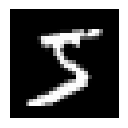

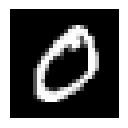

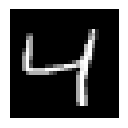

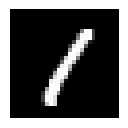

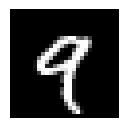

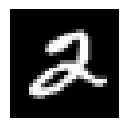

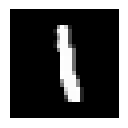

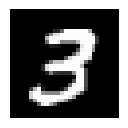

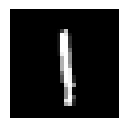

In [5]:
#from matplotlib import pyplot
for i in range(9):  
    plt.subplot(3,3,1+i)
    plt.imshow(x_train[i], cmap=plt.get_cmap('gray'))
    plt.axis('off')
    plt.show()

# Build the model




In [6]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

C:\Users\Chan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


# Compile the model

In [7]:
model.compile(optimizer=Adam(),
              loss=SparseCategoricalCrossentropy(),
              metrics=[SparseCategoricalAccuracy()])

# Train the model


In [8]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.2503 - sparse_categorical_accuracy: 0.9264 - val_loss: 0.1199 - val_sparse_categorical_accuracy: 0.9615
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.1061 - sparse_categorical_accuracy: 0.9684 - val_loss: 0.0862 - val_sparse_categorical_accuracy: 0.9720
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0738 - sparse_categorical_accuracy: 0.9767 - val_loss: 0.0817 - val_sparse_categorical_accuracy: 0.9747
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0545 - sparse_categorical_accuracy: 0.9830 - val_loss: 0.0811 - val_sparse_categorical_accuracy: 0.9762
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0436 - sparse_categorical_accuracy: 0.9860 - val_loss: 0.0769 - val_sparse_categorical_accuracy: 0.9780
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0360 - sparse_categorical_accuracy: 0.9879 - val_loss: 0.0802 - val_sparse_categorical_accuracy:

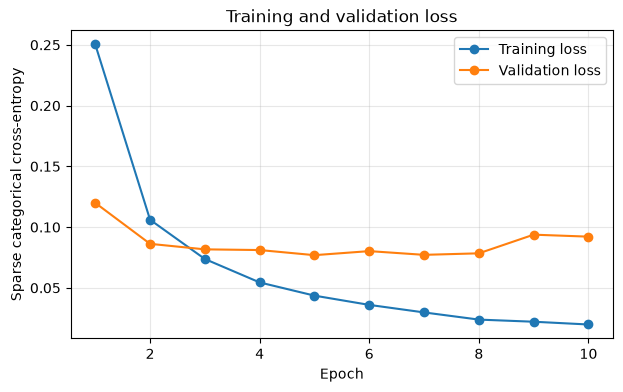

In [9]:
# training and validation loss vs. epochs
epochs = range(1, len(history.history['loss']) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, history.history['loss'], '-o', label='Training loss')
plt.plot(epochs, history.history['val_loss'], '-o', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epoch')
plt.ylabel('Sparse categorical cross-entropy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


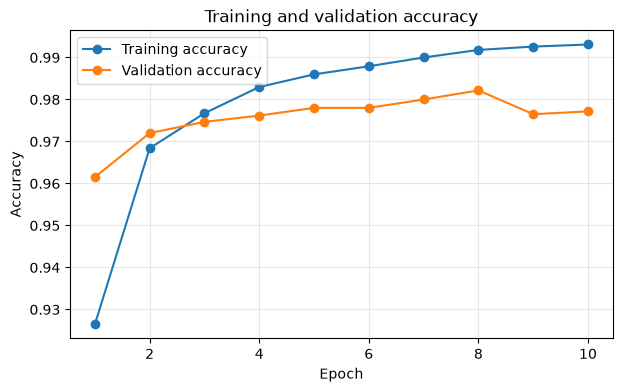

In [10]:
# training and validation accuracy vs. epochs
epochs = range(1, len(history.history['sparse_categorical_accuracy']) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, history.history['sparse_categorical_accuracy'], '-o', label='Training accuracy')
plt.plot(epochs, history.history['val_sparse_categorical_accuracy'], '-o', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


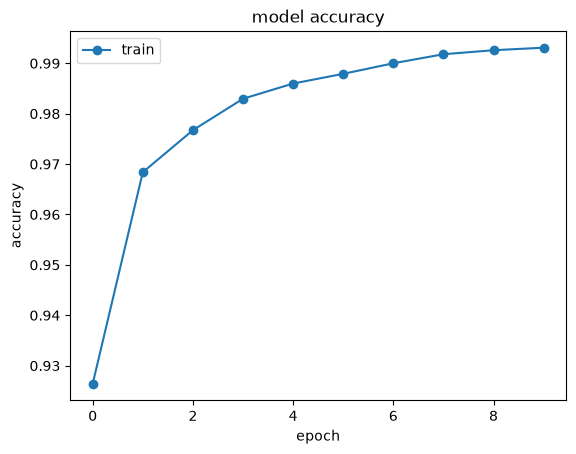

In [11]:
# summarize history for accuracy
plt.plot(history.history['sparse_categorical_accuracy'],'-o')
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

# evaluate the model

In [12]:
# evaluate the trained model on the test dataset
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

# Display final test results
print(f"Final test loss: {test_loss:.4f}")
print(f"Final test accuracy: {test_acc:.2%}")

Final test loss: 0.0882
Final test accuracy: 97.84%


In [13]:
# Test loss is one final evaluation value, not a per-epoch curve.
print(f"Final test loss: {test_loss:.4f}")
print(f"Final test accuracy: {test_acc:.4%}")


Final test loss: 0.0882
Final test accuracy: 97.8400%


# Part 1: mods




In [14]:
from tensorflow.keras.callbacks import EarlyStopping

def build_ann(hidden_units=(128, 64), activation='relu'):
    layers = [Flatten(input_shape=(28, 28))]
    for units in hidden_units:
        layers.append(Dense(units, activation=activation))
    layers.append(Dense(10, activation='softmax'))
    net = Sequential(layers)
    net.compile(
        optimizer=Adam(),
        loss=SparseCategoricalCrossentropy(),
        metrics=[SparseCategoricalAccuracy(name='accuracy')]
    )
    return net

def run_experiment(name, hidden_units=(128, 64), activation='relu', epochs=10):
    net = build_ann(hidden_units=hidden_units, activation=activation)
    hist = net.fit(
        x_train, y_train,
        validation_split=0.1,
        epochs=epochs,
        batch_size=32,
        verbose=1
    )
    test_loss, test_accuracy = net.evaluate(x_test, y_test, verbose=0)
    result = {
        'name': name,
        'architecture': str(hidden_units),
        'activation': activation,
        'epochs': epochs,
        'final_train_accuracy': hist.history['accuracy'][-1],
        'final_val_accuracy': hist.history['val_accuracy'][-1],
        'test_accuracy': test_accuracy,
        'test_loss': test_loss,
        'history': hist,
        'model': net
    }
    print(
        f"{name}: train accuracy={result['final_train_accuracy']:.4%}, "
        f"validation accuracy={result['final_val_accuracy']:.4%}, "
        f"test accuracy={test_accuracy:.4%}, test loss={test_loss:.4f}"
    )
    return result


In [15]:
# Baseline and controlled modifications
# Run all experiments for a fair comparison; training time depends on your computer.
results = []
results.append(run_experiment('Baseline: 128-64 ReLU, 10 epochs',
                              hidden_units=(128, 64), activation='relu', epochs=10))
results.append(run_experiment('One hidden layer: 128 ReLU, 10 epochs',
                              hidden_units=(128,), activation='relu', epochs=10))
results.append(run_experiment('Wider layers: 256-128 ReLU, 10 epochs',
                              hidden_units=(256, 128), activation='relu', epochs=10))
results.append(run_experiment('Three hidden layers: 128-64-32 ReLU, 10 epochs',
                              hidden_units=(128, 64, 32), activation='relu', epochs=10))
results.append(run_experiment('Baseline architecture with tanh, 10 epochs',
                              hidden_units=(128, 64), activation='tanh', epochs=10))
results.append(run_experiment('Baseline architecture, 5 epochs',
                              hidden_units=(128, 64), activation='relu', epochs=5))
results.append(run_experiment('Baseline architecture, 15 epochs',
                              hidden_units=(128, 64), activation='relu', epochs=15))


Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9247 - loss: 0.2547 - val_accuracy: 0.9665 - val_loss: 0.1115
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9666 - loss: 0.1084 - val_accuracy: 0.9715 - val_loss: 0.0977
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9764 - loss: 0.0740 - val_accuracy: 0.9730 - val_loss: 0.0908
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9825 - loss: 0.0558 - val_accuracy: 0.9787 - val_loss: 0.0783
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9864 - loss: 0.0421 - val_accuracy: 0.9790 - val_loss: 0.0850
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9883 - loss: 0.0359 - val_accuracy: 0.9778 - val_loss: 0.0844
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9894 - loss: 0.0308 - val_accuracy: 0.9792 - val_loss: 0.0931
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9919 - loss: 0.0231 - 

# Part 2: results and visualize

In [16]:
# summarize all results
import pandas as pd

summary = pd.DataFrame([{
    'Experiment': r['name'],
    'Hidden units': r['architecture'],
    'Activation': r['activation'],
    'Epochs': r['epochs'],
    'Training accuracy': r['final_train_accuracy'],
    'Validation accuracy': r['final_val_accuracy'],
    'Test accuracy': r['test_accuracy'],
    'Test loss': r['test_loss']
} for r in results])
summary


,Experiment,Hidden units,Activation,Epochs,Training accuracy,Validation accuracy,Test accuracy,Test loss
0,"Baseline: 128-64 ReLU, 10 epochs","(128, 64)",relu,10,0.993815,0.980000,0.9791,0.088636
1,"One hidden layer: 128 ReLU, 10 epochs","(128,)",relu,10,0.994741,0.979000,0.9786,0.081608
2,"Wider layers: 256-128 ReLU, 10 epochs","(256, 128)",relu,10,0.994630,0.982667,0.9792,0.089339
3,"Three hidden layers: 128-64-32 ReLU, 10 epochs","(128, 64, 32)",relu,10,0.992481,0.973000,0.9720,0.125579
4,"Baseline architecture with tanh, 10 epochs","(128, 64)",tanh,10,0.995037,0.978667,0.9764,0.084232
5,"Baseline architecture, 5 epochs","(128, 64)",relu,5,0.984722,0.975333,0.9749,0.086768
6,"Baseline architecture, 15 epochs","(128, 64)",relu,15,0.995333,0.977833,0.9772,0.111080


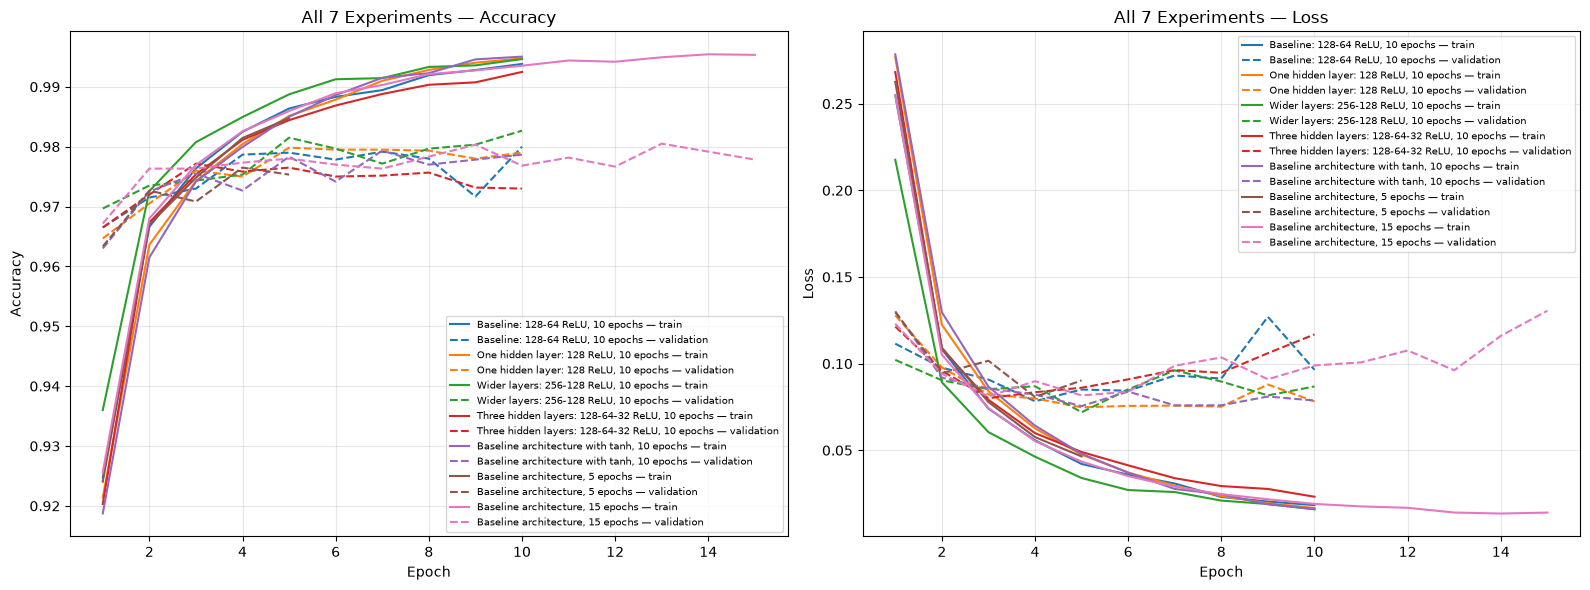

In [17]:

# compare training/validation curves for all 7 variations
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for i, result in enumerate(results):
    h = result['history']
    ep = range(1, len(h.history['loss']) + 1)
    color = f'C{i}'

    # Accuracy
    axes[0].plot(
        ep, h.history['accuracy'],
        color=color, linestyle='-',
        label=f"{result['name']} — train"
    )
    axes[0].plot(
        ep, h.history['val_accuracy'],
        color=color, linestyle='--',
        label=f"{result['name']} — validation"
    )

    # Loss
    axes[1].plot(
        ep, h.history['loss'],
        color=color, linestyle='-',
        label=f"{result['name']} — train"
    )
    axes[1].plot(
        ep, h.history['val_loss'],
        color=color, linestyle='--',
        label=f"{result['name']} — validation"
    )

axes[0].set_title('All 7 Experiments — Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=7, loc='best')

axes[1].set_title('All 7 Experiments — Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=7, loc='best')

plt.tight_layout()
plt.show()



# Color: Identifies one of the seven experiments.
# Solid line: Training performance.
# Dashed line: Validation performance.

# Part 3: report

## mods and results
<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Experiment</th>
      <th>Hidden units</th>
      <th>Activation</th>
      <th>Epochs</th>
      <th>Training accuracy</th>
      <th>Validation accuracy</th>
      <th>Test accuracy</th>
      <th>Test loss</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>Baseline: 128-64 ReLU, 10 epochs</td>
      <td>(128, 64)</td>
      <td>relu</td>
      <td>10</td>
      <td>0.993815</td>
      <td>0.980000</td>
      <td>0.9791</td>
      <td>0.088636</td>
    </tr>
    <tr>
      <th>1</th>
      <td>One hidden layer: 128 ReLU, 10 epochs</td>
      <td>(128,)</td>
      <td>relu</td>
      <td>10</td>
      <td>0.994741</td>
      <td>0.979000</td>
      <td>0.9786</td>
      <td>0.081608</td>
    </tr>
    <tr>
      <th>2</th>
      <td>Wider layers: 256-128 ReLU, 10 epochs</td>
      <td>(256, 128)</td>
      <td>relu</td>
      <td>10</td>
      <td>0.994630</td>
      <td>0.982667</td>
      <td>0.9792</td>
      <td>0.089339</td>
    </tr>
    <tr>
      <th>3</th>
      <td>Three hidden layers: 128-64-32 ReLU, 10 epochs</td>
      <td>(128, 64, 32)</td>
      <td>relu</td>
      <td>10</td>
      <td>0.992481</td>
      <td>0.973000</td>
      <td>0.9720</td>
      <td>0.125579</td>
    </tr>
    <tr>
      <th>4</th>
      <td>Baseline architecture with tanh, 10 epochs</td>
      <td>(128, 64)</td>
      <td>tanh</td>
      <td>10</td>
      <td>0.995037</td>
      <td>0.978667</td>
      <td>0.9764</td>
      <td>0.084232</td>
    </tr>
    <tr>
      <th>5</th>
      <td>Baseline architecture, 5 epochs</td>
      <td>(128, 64)</td>
      <td>relu</td>
      <td>5</td>
      <td>0.984722</td>
      <td>0.975333</td>
      <td>0.9749</td>
      <td>0.086768</td>
    </tr>
    <tr>
      <th>6</th>
      <td>Baseline architecture, 15 epochs</td>
      <td>(128, 64)</td>
      <td>relu</td>
      <td>15</td>
      <td>0.995333</td>
      <td>0.977833</td>
      <td>0.9772</td>
      <td>0.111080</td>
    </tr>
  </tbody>
</table>
</div>

**Experiment 1:** baseline network
The baseline neural network contained two fully connected hidden layers with 128 and 64 neurons, respectively. Both layers use the ReLU function. The output layer has 10 neurons and uses softmax to produce a probability.

The baseline had a training accuracy of 99.38%, validation accuracy of 98%, and test accuracy of 97.91%. The final test loss was 0.0886. This is quite accurate at reading handwritten digits.

**Experiment 2:** One hidden layer
Reduced hidden layers to a single 128 nueron one. ReLu and 10 epochs retained. Achieved the highest test accuracy among the seven.

**Experiment 3:** Wider hidden layers
Increased layer sizes to 256 and 128. ReLu and 10 epochs retained. Increasing the layer width slightly increased training and test accuracy.

**Experiment 4:** Three hidden layers
Added a third layer of 32 neurons. ReLU and 10 epochs retained. Adding a third layer prodcued the highest test loss among the seven.

**Experiment 5:** Tanh activation
Replaced ReLU with tanh. 128-64 and 10 epochs retained. Replacing the activation model decreaced test accuracy, implying ReLU is more effective.

**Experiment 6:** 5 epochs
Reduced number of epochs from baseline, all else retained.
Reducing epochs produced the lowest test loss among the seven.

**Experiment 7:** 15 epochs
Increased epochs from baselines, all else retained. Training accuracy slightly improved, no other meaningful improvement with increased epochs.


# predictions



Predicted labels: [7 2 1 0 4 1 4 9 6 9]
True labels:      [7 2 1 0 4 1 4 9 5 9]


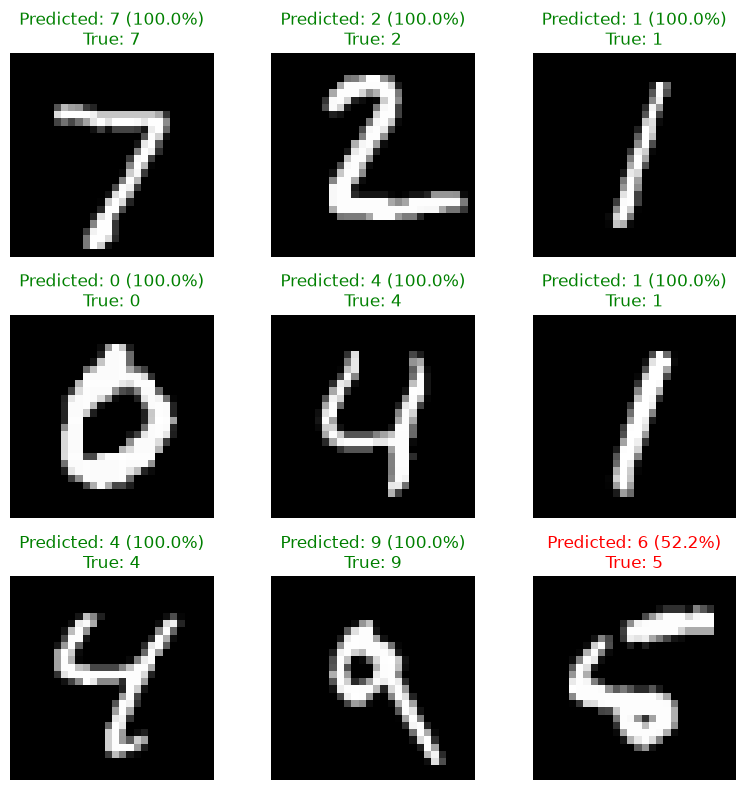

In [18]:
# predict
prediction_probabilities = model.predict(x_test, verbose=0)
predicted_labels = np.argmax(prediction_probabilities, axis=1)

print("Predicted labels:", predicted_labels[:10])
print("True labels:     ", y_test[:10])

fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    confidence = prediction_probabilities[i, predicted_labels[i]]
    ax.imshow(x_test[i], cmap="gray")
    ax.set_title(
        f"Predicted: {predicted_labels[i]} ({confidence:.1%})\nTrue: {y_test[i]}",
        color="green" if predicted_labels[i] == y_test[i] else "red"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

## Predict one image

Use this helper with any 28 × 28 grayscale image. It accepts either normalized pixel values (0–1) or standard pixel values (0–255).

In [19]:
def predict_digit(image):
    image = np.asarray(image, dtype=np.float32)
    if image.shape != (28, 28):
        raise ValueError(f"Expected an image with shape (28, 28), but got {image.shape}")
    if image.max() > 1.0:
        image = image / 255.0

    probabilities = model.predict(image[np.newaxis, ...], verbose=0)[0]
    predicted_digit = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_digit])
    return predicted_digit, confidence, probabilities

# Example: predict the first test image
digit, confidence, probabilities = predict_digit(x_test[0])
print(f"Predicted digit: {digit}")
print(f"Confidence: {confidence:.1%}")
print(f"True label: {y_test[0]}")

Predicted digit: 7
Confidence: 100.0%
True label: 7


In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,160 (1.25 MB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 218,774 (854.59 KB)